# Horse Training Data Analysis and Visualization

This Jupyter Notebook focuses on analyzing and visualizing horse training data using metrics derived from a JSON dataset. The primary objectives include:

1. **Data Processing**:
   - Load and parse a JSON file containing horse training data.
   - Flatten nested structures into a tabular format using pandas for easier analysis.
   - Sort and clean the data for visualization.

2. **Visualization of Metrics**:
   - **Trot Distance Load**: Visualize the daily trot distance load for each horse over time, both individually and in subplots for all horses.
   - **ACWR Metrics**: Analyze and plot Acute:Chronic Workload Ratio (ACWR) metrics for:
     - Distance
     - Duration
     - iTrimp (internal training load)
   - Highlight risk categories (e.g., undertraining, optimal, overreaching, overtraining) based on ACWR thresholds.

3. **Combined ACWR Comparison**:
   - Compare multiple ACWR metrics (Distance, Duration, iTrimp) for each horse in a single plot.

The notebook uses Python libraries such as `pandas`, `matplotlib`, and `seaborn` for data manipulation and visualization. It provides insights into horse training performance and workload management, helping identify trends and potential risks.

In [47]:
import json
import pandas as pd

# Use relative path to the file
path_horse_readiness_json = "datasets/Horse_Readiness_FULLY_FIXED.json"


with open(path_horse_readiness_json, "r", encoding="utf-8") as f:
    data = json.load(f)

records = []

for entry in data:
    horse_id = entry.get("HorseID", "unknown")
    acwr = entry.get("ACWR", {})

    for date, metrics in acwr.items():
        flat_record = {"HorseID": horse_id, "Date": date}

        for category, submetrics in metrics.items():
            for subname, values in submetrics.items():
                for k, v in values.items():
                    column_name = f"{category}_{subname}_{k}"
                    flat_record[column_name] = float(v) if v.replace('.', '', 1).isdigit() else v

        records.append(flat_record)

df = pd.DataFrame(records)

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df.sort_values(["HorseID", "Date"], inplace=True)

display(df.sample(4))

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
2144,483,2024-09-16,5.69,15.47,13.62,10.82,1.26,4.94,12.46,8.35,...,0.0,0.00,0.28,0.41,0.68,0.00,0.00,0.02,0.07,0.29
1080,311,2023-02-05,0.00,0.00,0.02,0.07,0.29,0.00,0.00,0.02,...,0.0,0.00,0.02,0.07,0.29,0.00,0.00,0.02,0.07,0.29
1089,311,2023-02-14,0.00,0.00,0.02,0.07,0.29,0.00,0.00,0.02,...,0.0,0.00,0.02,0.07,0.29,0.00,0.00,0.02,0.07,0.29
1538,311,2024-05-09,11.38,37.74,44.66,40.59,1.10,2.43,10.22,12.96,...,0.0,8.42,13.53,11.03,1.23,3.16,3.16,1.14,0.70,1.63


## Combined ACWR Comparison Plot per Horse

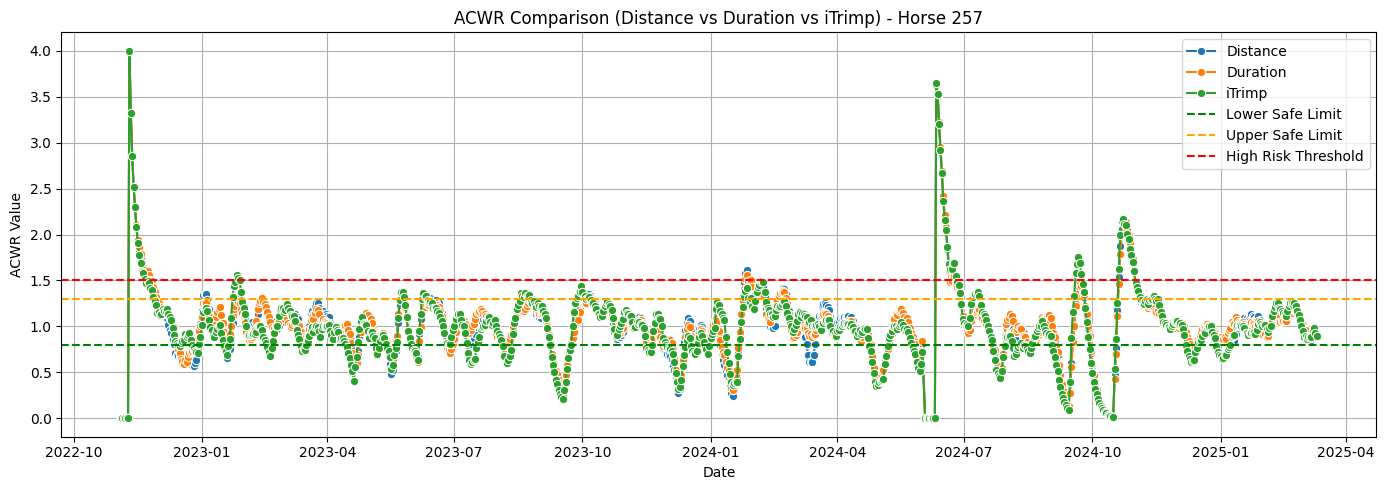

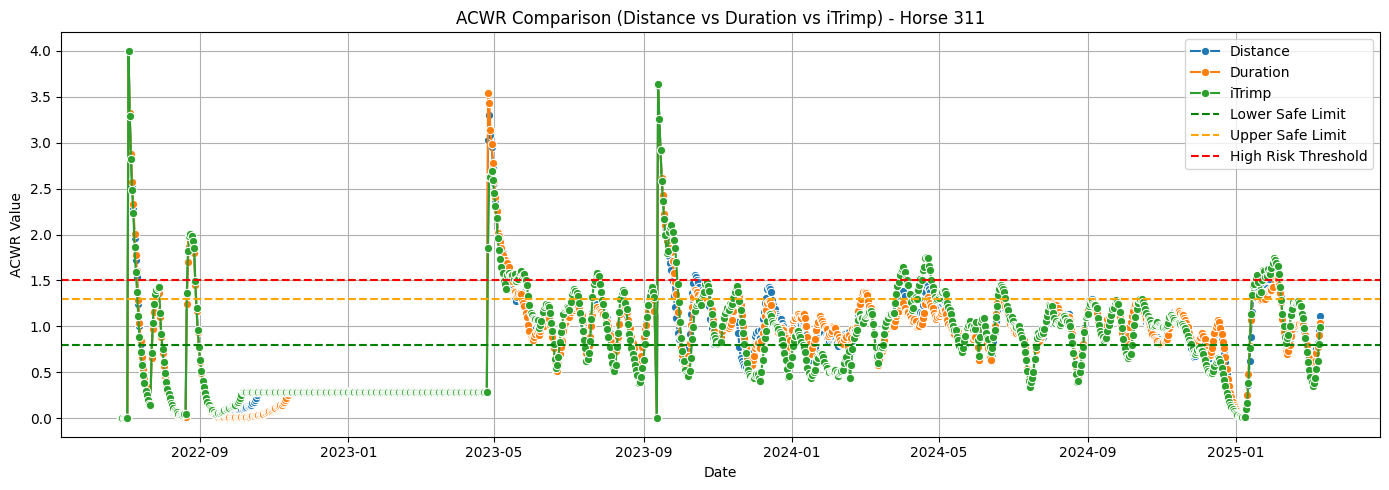

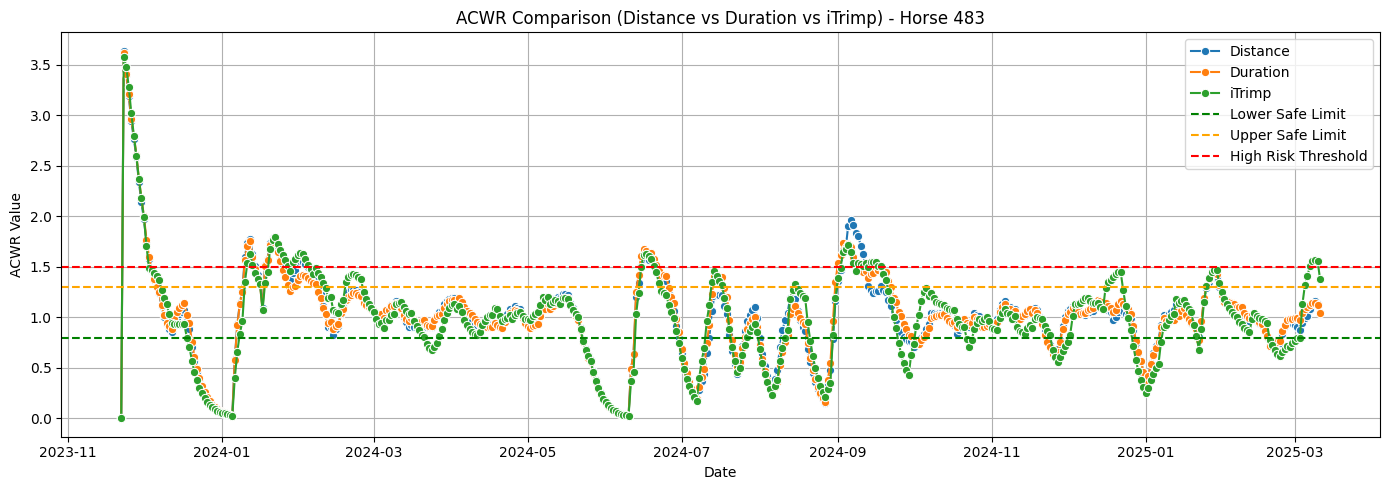

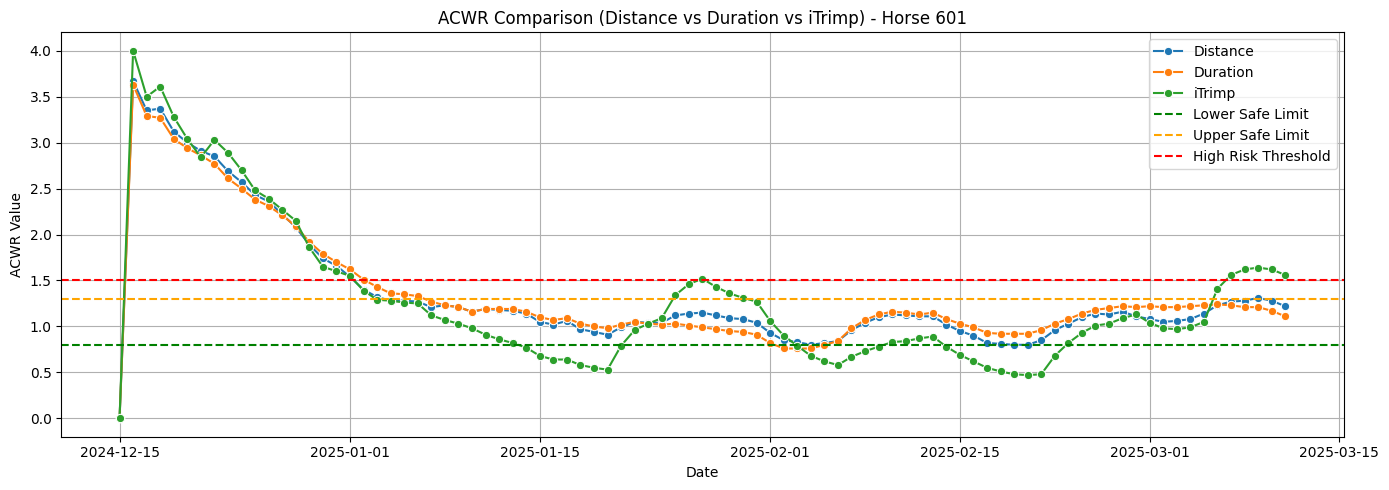

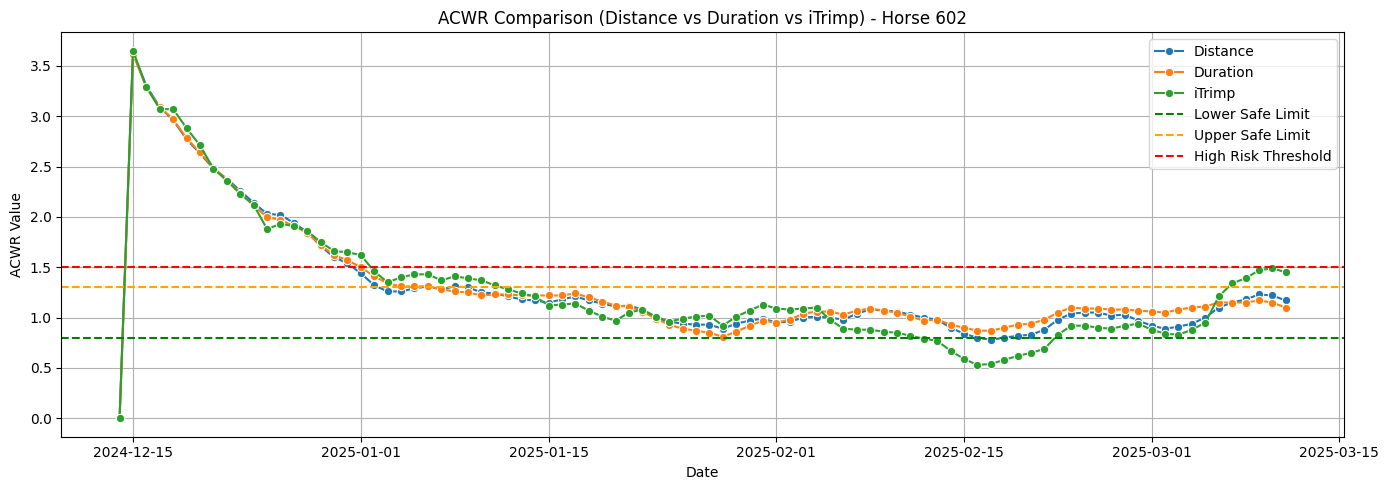

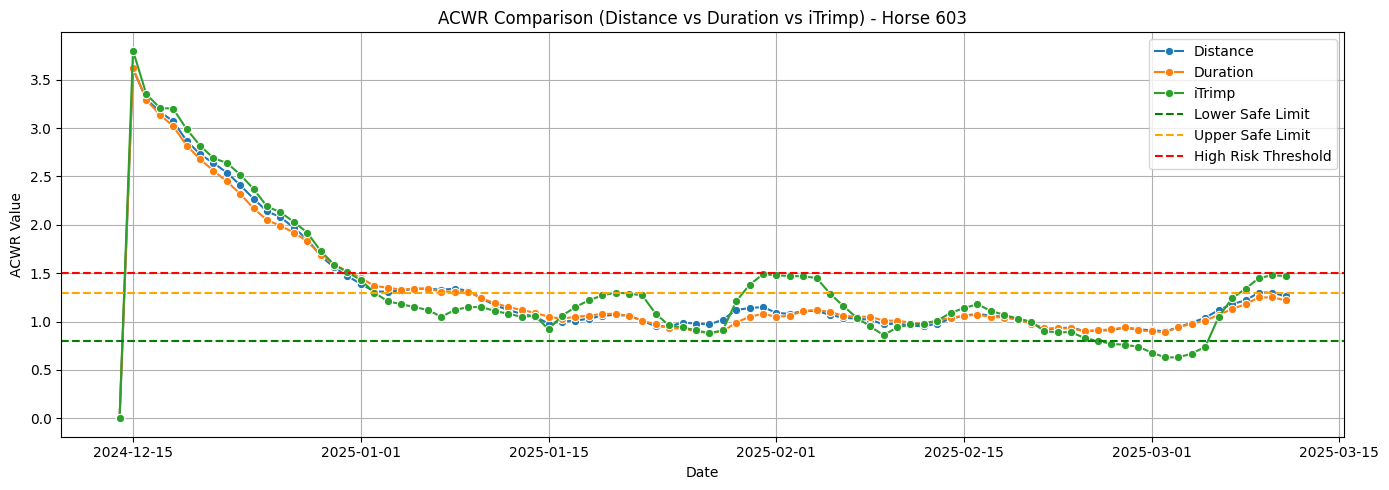

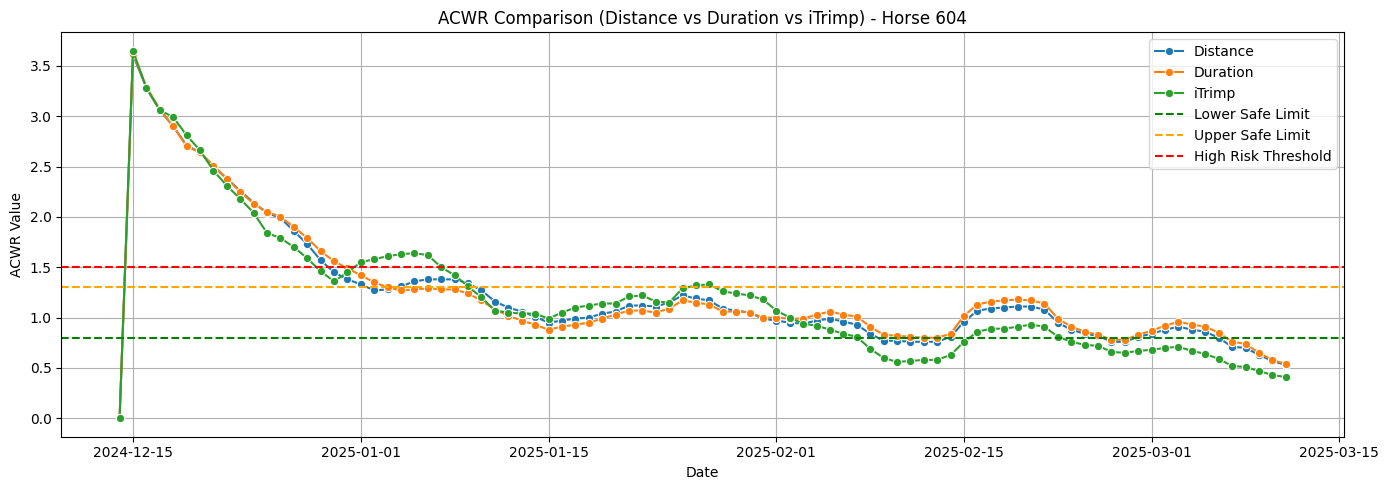

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the 3 ACWR metric columns
acwr_cols = {
    'Distance': 'externalDistance_Distance_ACWR',
    'Duration': 'externalDuration_Duration_ACWR',
    'iTrimp': 'iTrimp_overall_ACWR'
}

# Prepare data: keep only relevant columns
acwr_df = df[['HorseID', 'Date'] + list(acwr_cols.values())].dropna()

# Convert to float
for col in acwr_cols.values():
    acwr_df[col] = acwr_df[col].astype(float)

# Melt to long format for seaborn
df_melted = acwr_df.melt(id_vars=['HorseID', 'Date'], 
                         value_vars=acwr_cols.values(), 
                         var_name='ACWR_Type', 
                         value_name='ACWR_Value')

# Optional: map technical column names to readable ones
df_melted['ACWR_Type'] = df_melted['ACWR_Type'].map({
    'externalDistance_Distance_ACWR': 'Distance',
    'externalDuration_Duration_ACWR': 'Duration',
    'iTrimp_overall_ACWR': 'iTrimp'
})

# Get unique horses
horses = df_melted['HorseID'].unique()

# Plot all three metrics for each horse
for horse_id in horses:
    horse_df = df_melted[df_melted['HorseID'] == horse_id]

    plt.figure(figsize=(14, 5))
    sns.lineplot(data=horse_df, x='Date', y='ACWR_Value', hue='ACWR_Type', marker='o')
    
    # Thresholds
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold')

    plt.title(f'ACWR Comparison (Distance vs Duration vs iTrimp) - Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Data cleaning
We are to drop the first 4 months for every horse, since they are not correct data

In [49]:
one_month_cutoff = df.groupby('HorseID')["Date"].transform(
    lambda s: s.min() + pd.DateOffset(months=1)   # earliest date + 1 month
)

df_clean = df[df["Date"] >= one_month_cutoff].copy()

df_clean.head(2)

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
30,257,2022-12-04,7.02,38.37,35.25,30.47,1.16,1.0,9.72,9.80,...,6.37,15.06,10.45,9.57,1.09,0.0,0.0,0.0,0.0,0.0
31,257,2022-12-05,0.00,31.71,34.37,30.56,1.12,0.0,8.30,9.43,...,0.00,12.41,10.94,9.77,1.12,0.0,0.0,0.0,0.0,0.0


### One Plot for each horse

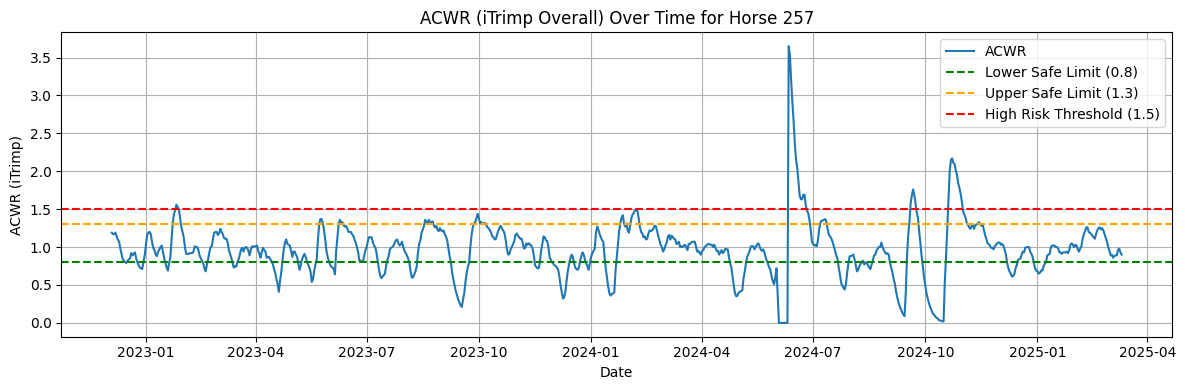

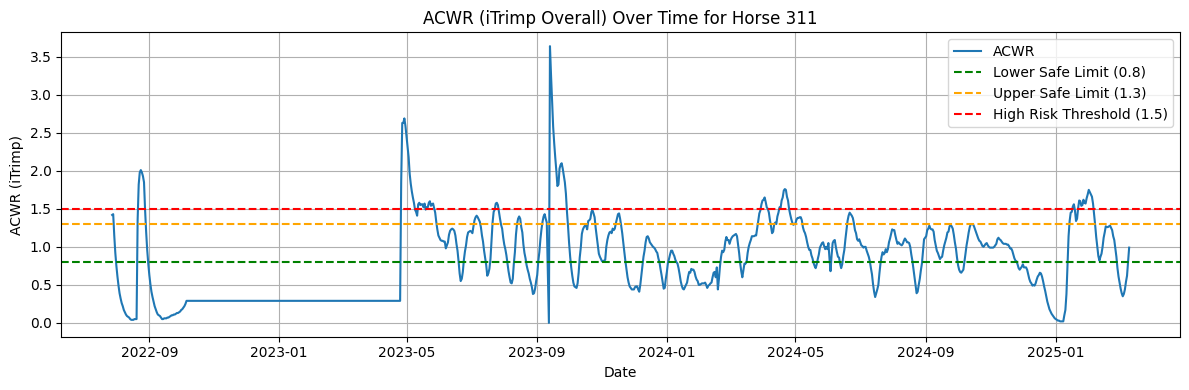

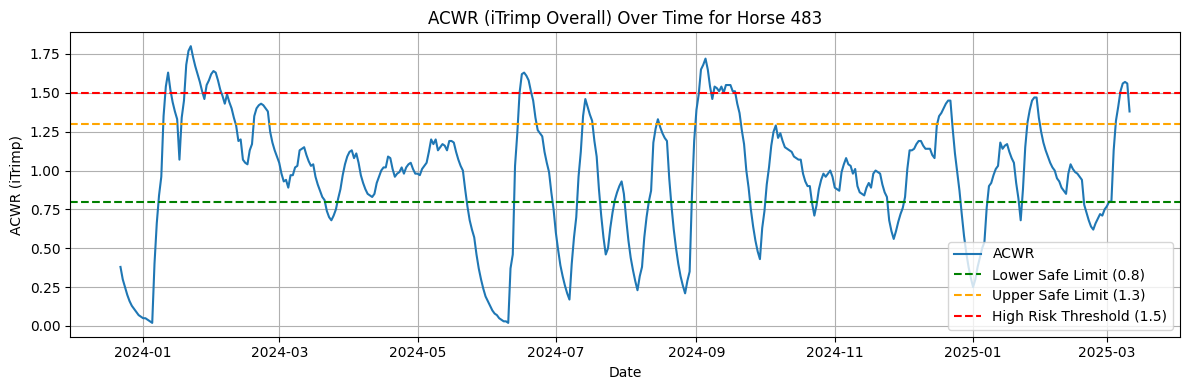

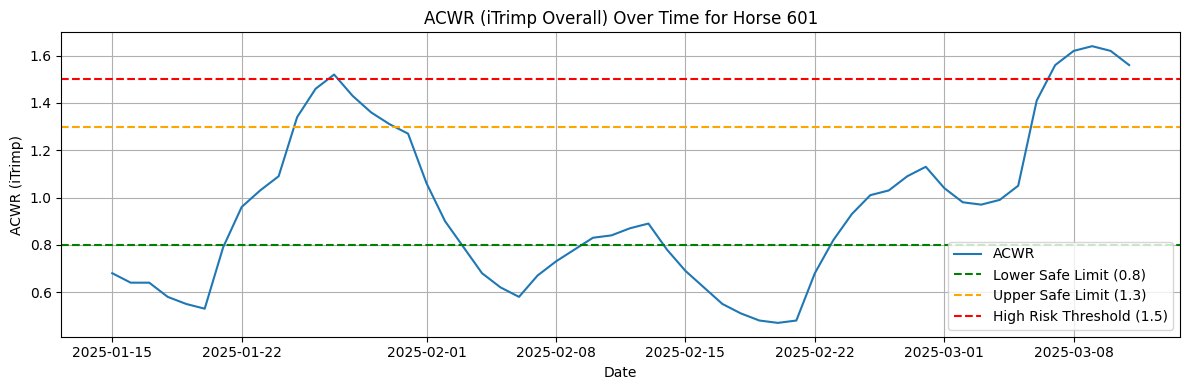

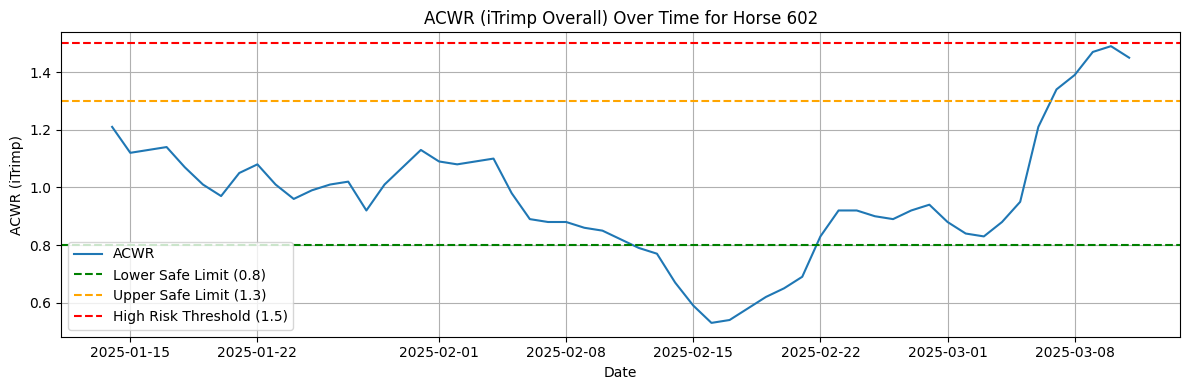

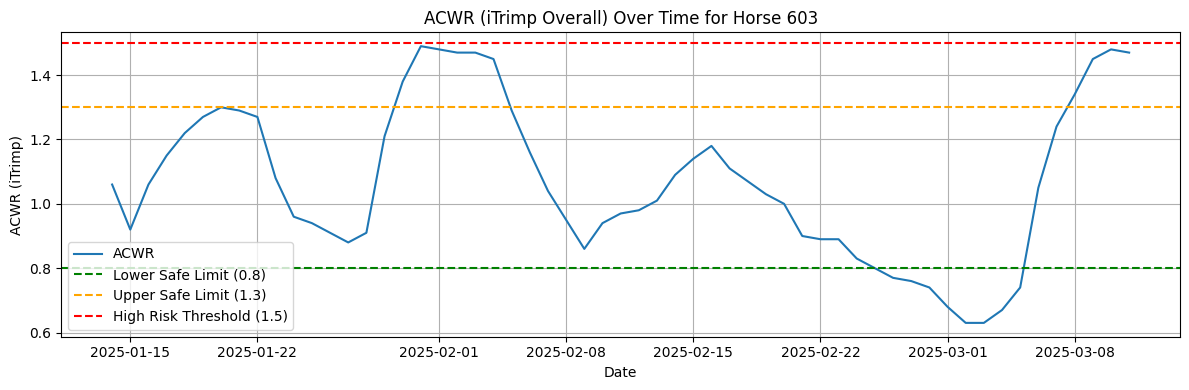

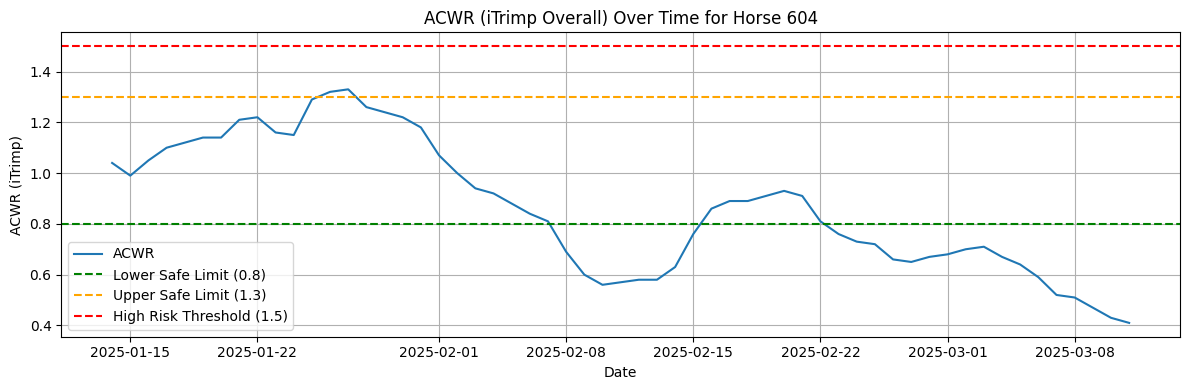

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ACWR metric for internal training load
acwr_col = 'iTrimp_overall_ACWR'

# Filter and clean
df_acwr = df_clean[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: tag risk levels
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # ACWR safe zone lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (iTrimp Overall) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (iTrimp)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### More plots for each horse

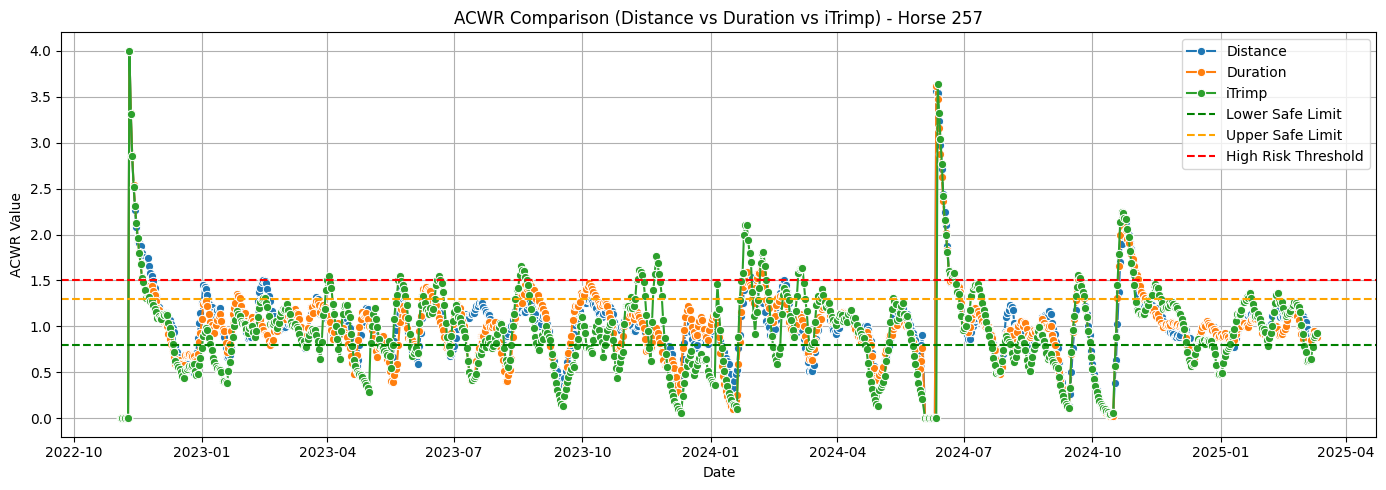

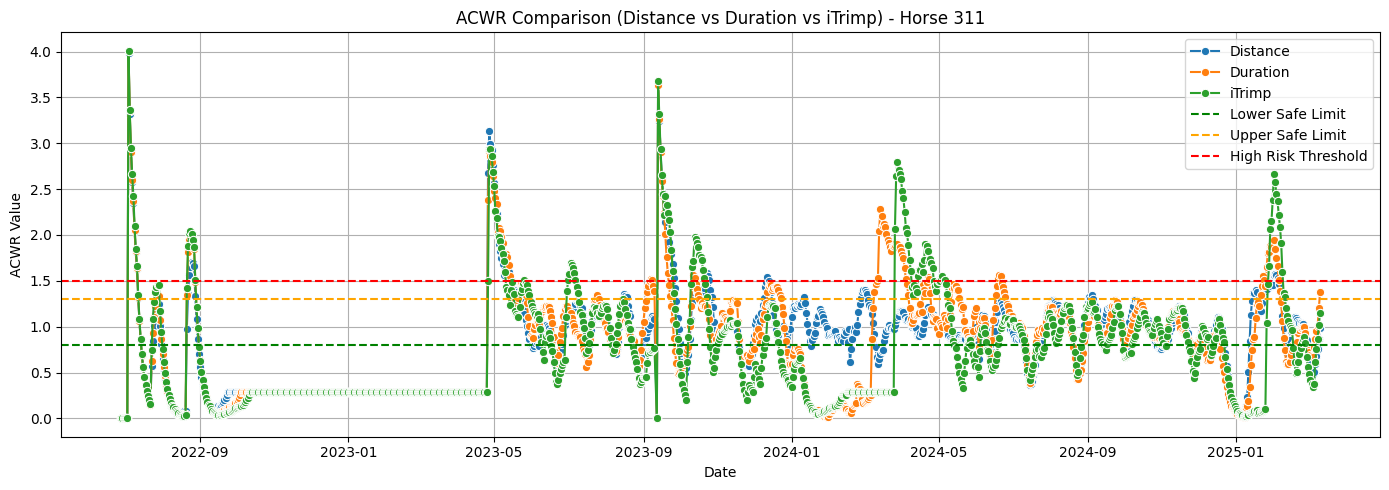

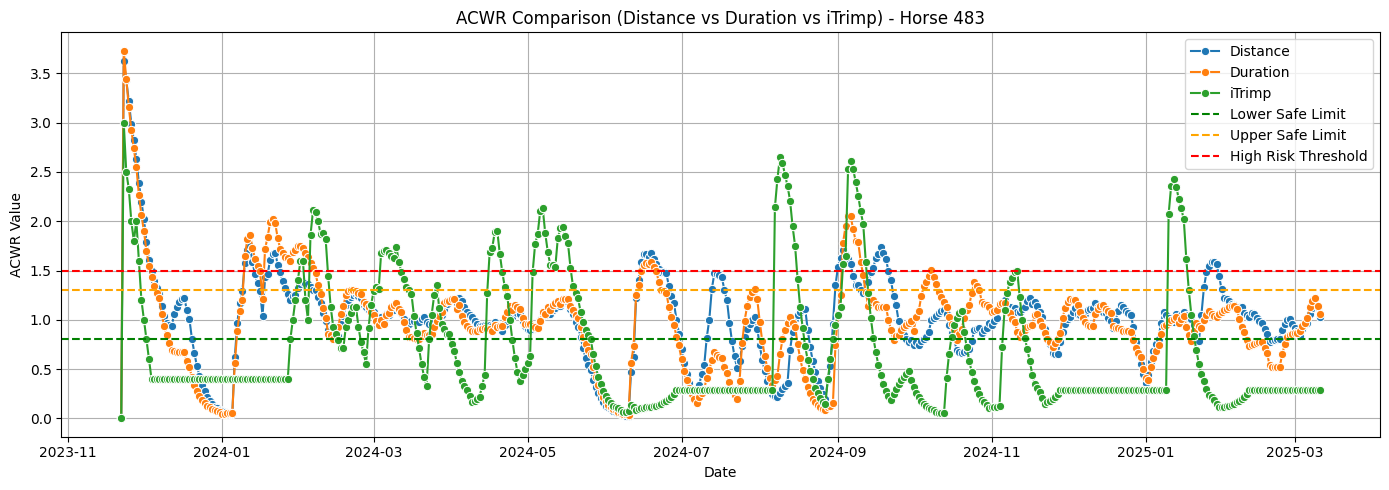

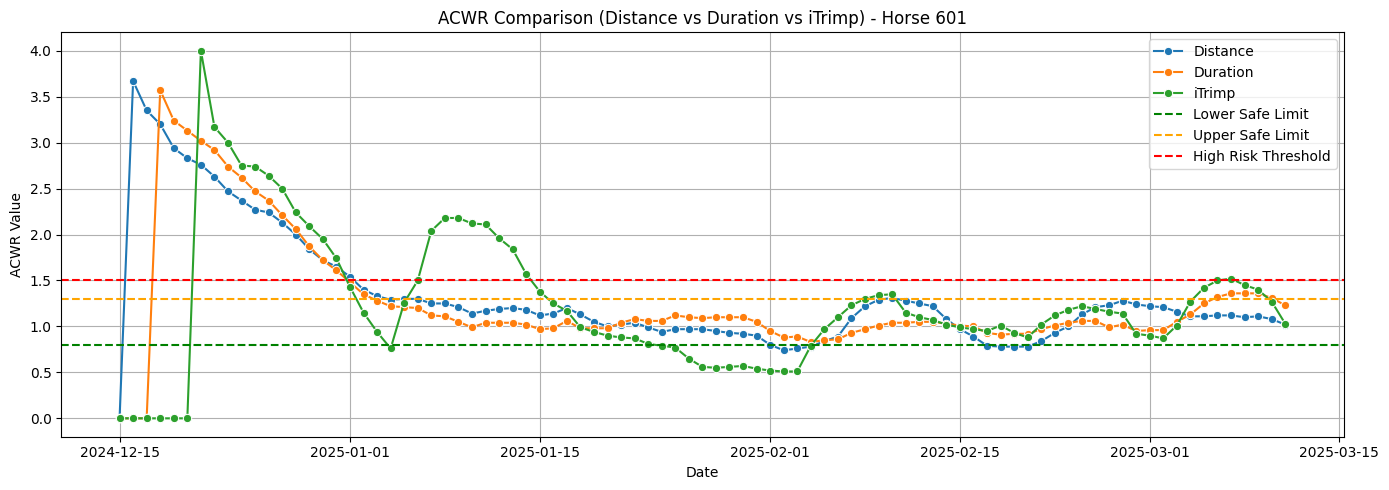

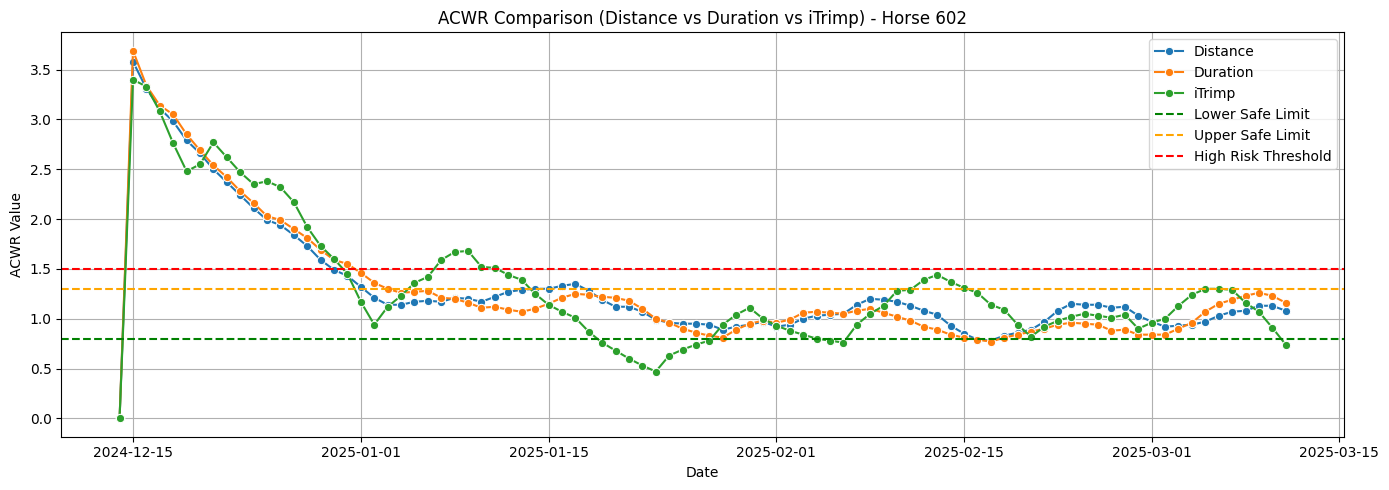

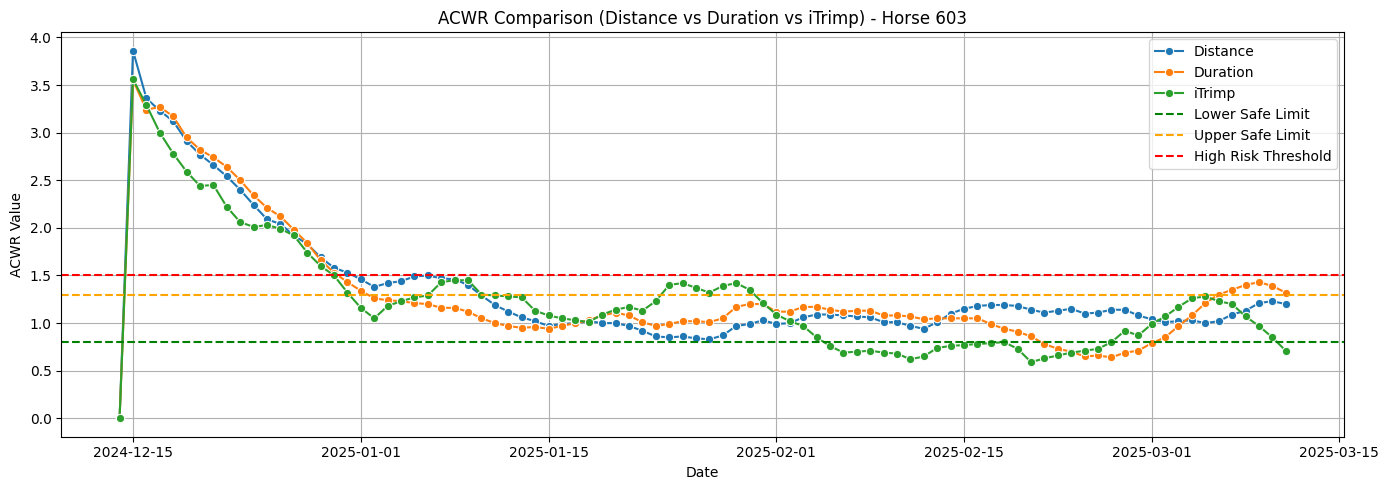

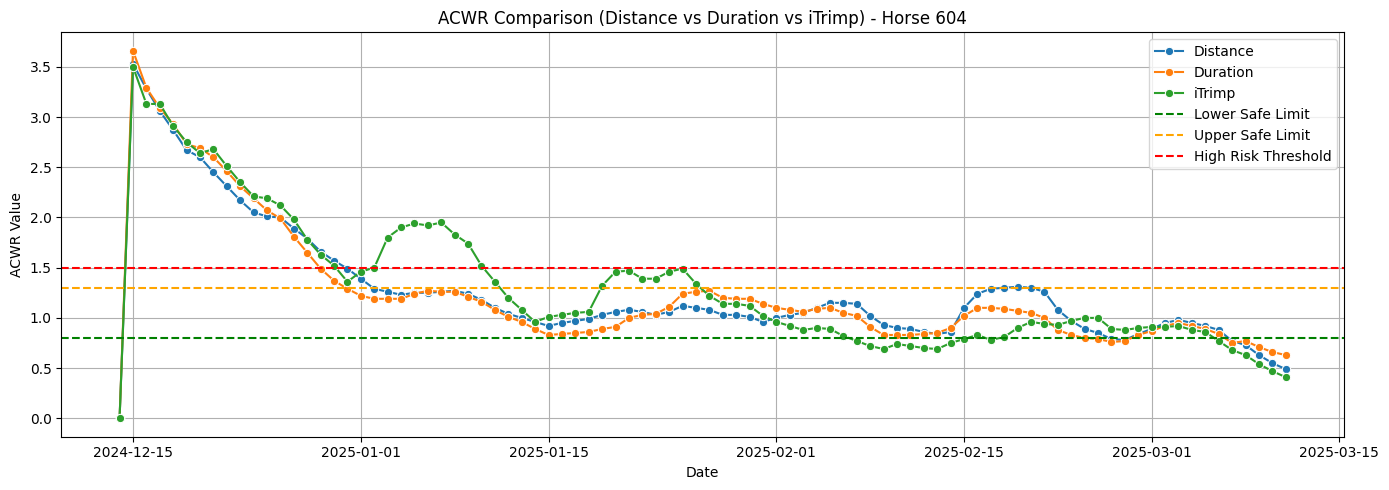

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the 3 ACWR metric columns
acwr_cols = {
    'Distance': 'externalDistance_Walk_Distance_ACWR',
    'Duration': 'externalDistance_Trot_Distance_ACWR',
    'iTrimp': 'externalDistance_Canter_SlowSpeed_ACWR'
}

# Prepare data: keep only relevant columns
acwr_df = df[['HorseID', 'Date'] + list(acwr_cols.values())].dropna()

# Convert to float
for col in acwr_cols.values():
    acwr_df[col] = acwr_df[col].astype(float)

# Melt to long format for seaborn
df_melted = acwr_df.melt(id_vars=['HorseID', 'Date'], 
                         value_vars=acwr_cols.values(), 
                         var_name='ACWR_Type', 
                         value_name='ACWR_Value')

# Optional: map technical column names to readable ones
df_melted['ACWR_Type'] = df_melted['ACWR_Type'].map({
    'externalDistance_Walk_Distance_ACWR': 'Distance',
    'externalDistance_Trot_Distance_ACWR': 'Duration',
    'externalDistance_Canter_SlowSpeed_ACWR': 'iTrimp'
})

# Get unique horses
horses = df_melted['HorseID'].unique()

# Plot all three metrics for each horse
for horse_id in horses:
    horse_df = df_melted[df_melted['HorseID'] == horse_id]

    plt.figure(figsize=(14, 5))
    sns.lineplot(data=horse_df, x='Date', y='ACWR_Value', hue='ACWR_Type', marker='o')
    
    # Thresholds
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold')

    plt.title(f'ACWR Comparison (Distance vs Duration vs iTrimp) - Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Generating Feedback with the Ollama Model

In this section, a large language model (LLM) is used to generate professional feedback for horse trainers based on recent ACWR (Acute:Chronic Workload Ratio) summaries. The approach involves:

- Summarizing the latest ACWR metrics and trends for a selected horse.
- Sending this summary as a prompt to the Ollama model (using the Mistral LLM) via a local command-line interface.
- Automatically generating a concise, expert-level feedback message tailored to the horse's recent workload and risk profile.


In [52]:
horse_id = "257"  # choose one horse
date_filter = "2025-03-10"  # choose a date filter
df_horse = df_clean[df_clean["HorseID"] == horse_id].copy()

# Define relevant columns
columns_to_include = [
    "Date",

    # Load_Today
    "iTrimp_overall_Load_Today",
    "iTrimp_walk_Load_Today",
    "iTrimp_trot_Load_Today",
    "iTrimp_canter_Load_Today",
    "iTrimp_galop_Load_Today",

    # ACWR
    "iTrimp_overall_ACWR",
    "iTrimp_walk_ACWR",
    "iTrimp_trot_ACWR",
    "iTrimp_canter_ACWR",
    "iTrimp_galop_ACWR",
]

# Filter out rows with missing values in any of those columns
df_horse = df_horse[columns_to_include].dropna()

# Convert ACWR columns to float (if needed)
acwr_columns = [col for col in columns_to_include if "ACWR" in col]
df_horse[acwr_columns] = df_horse[acwr_columns].astype(float)

df_horse.head(3)


,Date,iTrimp_overall_Load_Today,iTrimp_walk_Load_Today,iTrimp_trot_Load_Today,iTrimp_canter_Load_Today,iTrimp_galop_Load_Today,iTrimp_overall_ACWR,iTrimp_walk_ACWR,iTrimp_trot_ACWR,iTrimp_canter_ACWR,iTrimp_galop_ACWR
30,2022-12-04,8.24,0.53,6.25,6.37,0.0,1.19,1.24,1.12,1.09,0.0
31,2022-12-05,0.0,0.0,0.00,0.00,0.0,1.17,1.20,1.10,1.12,0.0
32,2022-12-06,3.08,1.92,1.84,0.73,0.0,1.17,1.23,1.10,1.15,0.0


In [53]:
# Check number of rows available
print("All available dates for horse:")
print(df_horse["Date"].sort_values().unique())

# See how many rows we have per week
df_horse["Week"] = df_horse["Date"].dt.to_period("W").apply(lambda r: r.start_time)
print("\nWeek counts:")
print(df_horse["Week"].value_counts().sort_index())


All available dates for horse:
<DatetimeArray>
['2022-12-04 00:00:00', '2022-12-05 00:00:00', '2022-12-06 00:00:00',
 '2022-12-07 00:00:00', '2022-12-08 00:00:00', '2022-12-09 00:00:00',
 '2022-12-10 00:00:00', '2022-12-11 00:00:00', '2022-12-12 00:00:00',
 '2022-12-13 00:00:00',
 ...
 '2025-03-02 00:00:00', '2025-03-03 00:00:00', '2025-03-04 00:00:00',
 '2025-03-05 00:00:00', '2025-03-06 00:00:00', '2025-03-07 00:00:00',
 '2025-03-08 00:00:00', '2025-03-09 00:00:00', '2025-03-10 00:00:00',
 '2025-03-11 00:00:00']
Length: 828, dtype: datetime64[ns]

Week counts:
Week
2022-11-28    1
2022-12-05    7
2022-12-12    7
2022-12-19    7
2022-12-26    7
             ..
2025-02-10    7
2025-02-17    7
2025-02-24    7
2025-03-03    7
2025-03-10    2
Name: count, Length: 120, dtype: int64


In [ ]:
import subprocess
import json

def generate_local_feedback(summary_text):
    prompt = f"""
You are an experienced equine sports scientist. Your task is to analyze the training data of a horse and provide a short, clear, and feedback message for the trainer. The tone should be expert, supportive, and practical.
Use the data below to:
- Comment on overall training load and balance.
- Highlight any gaits that are consistently undertrained, overtrained values (check Zone), or have erratic patterns.
- Be aware that horse does not train every day (check Load), so some days load = 0 (recovery days).
- Make personalized recommendations for load adjustment or rest.
- I will provide you with a summary of the training data, which includes date, and various metrics related to training load and ACWR (Acute:Chronic Workload Ratio) and Zone which classifies the effectiveness of the horse training.

Only provide the feedback with explanation.

--- Training Summary Start ---
{summary_text}
--- Training Summary End ---

Trainer Feedback:
"""
    
    # Send to Ollama (CLI mode)
    result = subprocess.run(
        ['ollama', 'run', 'mistral'],
        input=prompt.encode(),
        stdout=subprocess.PIPE
    )

    output = result.stdout.decode('utf-8')
    return output.strip()



Keep in mind that model might take time till its generate response. With this data for me it took 30-40 seconds but that would depend on a PC as well. That is why more data might naturally increase the time till the model will generate its response.

In [69]:
from datetime import timedelta

def get_risk_zone(acwr):
    if acwr < 0.8:
        return "Undertrained"
    elif acwr > 1.5:
        return "Overtrained"
    else:
        return "Optimal"

def summarize_recent_7_days(df_horse):
    df_recent = df_horse.sort_values("Date").tail(7)
    summary = "Recent 7 Days Training Summary:\n"

    for _, row in df_recent.iterrows():
        summary += f"{row['Date'].strftime('%Y-%m-%d')}:\n"
        for gait in ["walk", "trot", "canter", "galop"]:
            load = row[f"iTrimp_{gait}_Load_Today"]
            acwr = row[f"iTrimp_{gait}_ACWR"]
            zone = get_risk_zone(acwr) if load > 0 else "Not Trained"
            summary += f"  {gait.capitalize()} - Load: {load:.1f} | ACWR: {acwr:.2f} | Zone: {zone}\n"
    return summary

def summarize_weekly_averages(df_horse):
    df_sorted = df_horse.sort_values("Date")
    df_sorted['Week'] = df_sorted['Date'].dt.to_period('W').apply(lambda r: r.start_time)

    weeks = sorted(df_sorted['Week'].unique())[-6:-1]  # Previous 5 full weeks

    summary = "\nPrevious 5 Weeks Overview:\n"

    for week_start in weeks:
        week_data = df_sorted[df_sorted['Week'] == week_start]
        if len(week_data) == 0:
            continue
        avg_load = week_data["iTrimp_overall_Load_Today"].mean()
        avg_acwr = week_data["iTrimp_overall_ACWR"].mean()
        zone = get_risk_zone(avg_acwr)
        week_end = week_start + timedelta(days=6)
        summary += f"Week ({week_start.date()} to {week_end.date()}): Avg Load: {avg_load:.1f} | Avg ACWR: {avg_acwr:.2f} | Zone: {zone}\n"
    return summary

# Make sure Date column is datetime
df_horse["Date"] = pd.to_datetime(df_horse["Date"])

# Generate the summary text
summary_text = summarize_recent_7_days(df_horse) + "\n" + summarize_weekly_averages(df_horse)
print(summary_text)


Recent 7 Days Training Summary:
2025-03-05:
  Walk - Load: 1.1 | ACWR: 1.00 | Zone: Optimal
  Trot - Load: 3.9 | ACWR: 0.89 | Zone: Optimal
  Canter - Load: 2.7 | ACWR: 0.66 | Zone: Undertrained
  Galop - Load: 0.0 | ACWR: 0.50 | Zone: Not Trained
2025-03-06:
  Walk - Load: 0.0 | ACWR: 0.97 | Zone: Not Trained
  Trot - Load: 0.0 | ACWR: 0.93 | Zone: Not Trained
  Canter - Load: 0.0 | ACWR: 0.68 | Zone: Not Trained
  Galop - Load: 0.0 | ACWR: 0.50 | Zone: Not Trained
2025-03-07:
  Walk - Load: 0.8 | ACWR: 0.92 | Zone: Optimal
  Trot - Load: 1.2 | ACWR: 0.97 | Zone: Optimal
  Canter - Load: 0.2 | ACWR: 0.71 | Zone: Undertrained
  Galop - Load: 0.0 | ACWR: 0.50 | Zone: Not Trained
2025-03-08:
  Walk - Load: 1.8 | ACWR: 0.95 | Zone: Optimal
  Trot - Load: 2.9 | ACWR: 1.05 | Zone: Optimal
  Canter - Load: 5.5 | ACWR: 0.89 | Zone: Optimal
  Galop - Load: 0.0 | ACWR: 0.50 | Zone: Not Trained
2025-03-09:
  Walk - Load: 0.0 | ACWR: 0.93 | Zone: Not Trained
  Trot - Load: 0.0 | ACWR: 1.05 | Zone

In [70]:
# Pass to Mistral model for feedback
feedback = generate_local_feedback(summary_text)
print("\nFeedback for trainer:")
print(feedback)



Feedback for trainer:
Dear Trainer,

   I have analyzed the training data of your horse over the past week and the previous five weeks. The overall load seems well-balanced, with a mix of walks, trots, canters, and occasional gaits like galop. However, there are some areas that could benefit from further attention to optimize the horse's performance and reduce the risk of injury.

   Firstly, the galop training sessions have been inconsistent and non-existent for the past week. This gait plays a crucial role in building overall fitness and power, so it is recommended to incorporate more galop work into the training schedule, particularly on recovery days or during light training periods.

   Secondly, the canter load has shown an erratic pattern, with high values followed by low or no activity on some days. While the horse appears to handle these fluctuations reasonably well at present, maintaining a consistent canter load within the optimal zone would be beneficial for long-term fitn



iTrimp_overall_Load_Today,
iTrimp_walk_Load_Today,
iTrimp_trot_Load_Today,
iTrimp_canter_Load_Today,
iTrimp_galop_Load_Today,

overall load day should have sum of the load today from the horse gaits below. So first filter should check:
if load today is above 0 it means that horse participated in the gait
if load today is 0 it means it did not participated in it

iTrimp_overall_ACWR,
iTrimp_walk_ACWR,
iTrimp_trot_Load_ACWR,
iTrimp_canter_ACWR,
iTrimp_galop_ACWR,

and once we know the relevant gaits we shall be able to look at the acwr of specific gaits. the overall tells us how horse performs overall but if we want to make the feedback personal... the model should also know acwr of relevant gaits which specifically horse may slack or raise up too much.

so as input to the model I would like to have the current week data and then data to 5 weeks.



